# Global Solution — Classificação de roubo e furto com MLP

**Disciplina:** Aprendizado Profundo com Redes Neurais Convolucionais — FIAP  
**Aluno:** Lucas Mota | **RM:** 566670 | **Modalidade:** individual

## Objetivo
Comparar três arquiteturas de redes neurais **MLP** para classificar ocorrências já registradas na cidade de São Paulo como **furto** ou **roubo**. A melhor rede será salva e usada por uma aplicação web estática no GitHub Pages, sem servidor Python.

Além de comparar as três redes, o notebook (a) mostra qual seria a acurácia de um "modelo" que responde sempre *furto* (a referência mínima), (b) explora o que cada atributo informa sobre a classe e (c) ajusta o limiar de decisão usando só a validação, porque roubo é a classe menos frequente.

> **Limite importante:** este modelo não prevê se um crime vai acontecer. As porcentagens representam apenas a classificação de um registro com as características informadas.

**Fonte:** Secretaria da Segurança Pública do Estado de São Paulo (SSP-SP), [Portal de Estatísticas](https://www.ssp.sp.gov.br/estatistica/consultas). Arquivo original `SPDadosCriminais_2025.xlsx`, abas `JAN-JUN_2025` e `JUL-DEZ_2025`, fatos de 2025. No repositório há um CSV extraído desse arquivo somente com as colunas necessárias.

**Como usar no Colab:** execute as células na ordem. Na primeira execução, envie `ocorrencias_capital_2025.csv` (arquivo que está na pasta `dados/` do projeto). Não é preciso enviar `pipeline.py` nem executar outro script de treinamento.

## 1. Bibliotecas e arquivos
Usaremos **Pandas e NumPy** para os dados, **Scikit-learn** para dividir e codificar, **Keras** para as MLPs e **Matplotlib** para os gráficos. O código necessário está todo neste notebook.

In [1]:
from pathlib import Path
import json
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

SEMENTE = 42
ATRIBUTOS = ['bairro', 'periodo', 'tipo_local', 'dia_semana']
FONTE = 'https://www.ssp.sp.gov.br/estatistica/consultas'
keras.utils.set_random_seed(SEMENTE)

#No projeto a base está na pasta dados/. No Colab, ela pode ser enviada diretamente.
ARQUIVO = Path('dados/ocorrencias_capital_2025.csv')
if not ARQUIVO.exists():
    ARQUIVO = Path('ocorrencias_capital_2025.csv')
if not ARQUIVO.exists():
    try:
        from google.colab import files
        print('Envie o arquivo ocorrencias_capital_2025.csv (que está em dados/ no ZIP do projeto).')
        enviados = files.upload()
        ARQUIVO = Path('ocorrencias_capital_2025.csv')
        if not ARQUIVO.exists():
            raise FileNotFoundError('Escolha o arquivo ocorrencias_capital_2025.csv.')
    except ImportError:
        raise FileNotFoundError('Coloque o arquivo dados/ocorrencias_capital_2025.csv junto do projeto.')

print('Base encontrada:', ARQUIVO)
print('Keras:', keras.__version__)


Base encontrada: dados/ocorrencias_capital_2025.csv
Keras: 3.15.1


## 2. Exploração da base
O recorte CSV preserva informações do boletim necessárias para o filtro e a verificação de duplicidades. Não contém nomes de vítimas nem outros dados pessoais. São consideradas apenas as naturezas **FURTO - OUTROS** e **ROUBO - OUTROS**, porque são comparáveis entre si. A natureza será utilizada como **rótulo**, nunca como entrada da rede.

In [2]:
dados = pd.read_csv(ARQUIVO, dtype=str, keep_default_na=False)
print('Linhas no recorte:', len(dados))
print('Colunas:', list(dados.columns))
display(dados[['NOME_MUNICIPIO_CIRCUNSCRICAO', 'NATUREZA_APURADA', 'BAIRRO', 'DESC_PERIODO', 'DESCR_TIPOLOCAL']].head())
print('\nNaturezas no arquivo:')
print(dados['NATUREZA_APURADA'].value_counts())


Linhas no recorte: 346702
Colunas: ['NOME_DELEGACIA', 'NUM_BO', 'ANO_BO', 'DATA_OCORRENCIA_BO', 'DESC_PERIODO', 'DESCR_TIPOLOCAL', 'BAIRRO', 'NOME_MUNICIPIO_CIRCUNSCRICAO', 'NATUREZA_APURADA']


,NOME_MUNICIPIO_CIRCUNSCRICAO,NATUREZA_APURADA,BAIRRO,DESC_PERIODO,DESCR_TIPOLOCAL
0,S.PAULO,FURTO - OUTROS,LIBERDADE,NULL,Via Pública
1,S.PAULO,FURTO - OUTROS,LIBERDADE,NULL,Via Pública
2,S.PAULO,FURTO - OUTROS,CENTRO HISTÓRICO DE SÃO PAULO,NULL,Condomínio Comercial
3,S.PAULO,FURTO - OUTROS,CAMBUCI,NULL,Residência
4,S.PAULO,FURTO - OUTROS,SÉ,NULL,Via Pública



Naturezas no arquivo:
NATUREZA_APURADA
FURTO - OUTROS    250064
ROUBO - OUTROS     96638
Name: count, dtype: int64


## 3. Limpeza, seleção e construção das variáveis

**Recorte geográfico:** `NOME_MUNICIPIO_CIRCUNSCRICAO` identifica o município da ocorrência, diferente do local de registro do boletim.  
**Rótulo:** 0 = furto; 1 = roubo.  
**Duplicidades:** um mesmo BO pode ter vários itens; retiramos repetições e boletins com rótulos contraditórios.  
**Entradas:** bairro, período do dia, tipo de local e dia da semana. Elas descrevem o contexto do fato sem revelar diretamente sua natureza.  
**Ausências:** mantidas como `NAO INFORMADO`, sem criar dados fictícios.

**Por que estes quatro atributos?** Cada um responde a uma pergunta simples sobre o registro: *onde* (bairro e tipo de local) e *quando* (período do dia e dia da semana). São campos da base que descrevem o contexto do fato, sem revelar a natureza e sem dados pessoais. A seção 5.1 mede, só com o treino, quanto cada um ajuda de fato a separar furto de roubo.

In [3]:
def normalizar(valor):
    if pd.isna(valor):
        return ''
    texto = unicodedata.normalize('NFKD', str(valor))
    return ''.join(letra for letra in texto if not unicodedata.combining(letra)).upper().strip()

#Garantir que os nomes das colunas estejam normalizados.
df = dados.copy()
df.columns = [normalizar(coluna) for coluna in df.columns]
df = df.rename(columns={'NOME_MUNICIPIO_CIRCUNCRICAO': 'NOME_MUNICIPIO_CIRCUNSCRICAO'})

municipio = df['NOME_MUNICIPIO_CIRCUNSCRICAO'].map(normalizar)
df = df.loc[municipio.isin(['S.PAULO', 'SAO PAULO', 'SAOPAULO', 'SAO.PAULO'])].copy()
total_capital = len(df)

natureza = df['NATUREZA_APURADA'].map(normalizar)
furto = natureza.eq('FURTO - OUTROS')
roubo = natureza.eq('ROUBO - OUTROS')
df = df.loc[furto | roubo].copy()
df['classe'] = roubo.loc[df.index].astype(int)

#A planilha original utiliza datas numéricas do Excel.
numeros = pd.to_numeric(df['DATA_OCORRENCIA_BO'], errors='coerce')
datas = pd.to_datetime(numeros, unit='D', origin='1899-12-30', errors='coerce')
if numeros.isna().any():
    datas.loc[numeros.isna()] = pd.to_datetime(df.loc[numeros.isna(), 'DATA_OCORRENCIA_BO'], dayfirst=True, errors='coerce')
df = df.loc[datas.dt.year == 2025].copy()
datas = datas.loc[df.index]
total_2025 = len(df)

#BO identificado pela delegacia, ano e número; evitar contar itens como fatos independentes.
chave_bo = ['NOME_DELEGACIA', 'ANO_BO', 'NUM_BO']
ambiguos = df.groupby(chave_bo)['classe'].transform('nunique') > 1
bo_ambiguos = len(df.loc[ambiguos, chave_bo].drop_duplicates())
df = df.loc[~ambiguos].drop_duplicates(subset=chave_bo).copy()
total_unicos = len(df)

for destino, coluna in [('bairro', 'BAIRRO'), ('periodo', 'DESC_PERIODO'), ('tipo_local', 'DESCR_TIPOLOCAL')]:
    df[destino] = df[coluna].map(normalizar)
    df.loc[df[destino].isin(['', 'NULL', 'NAN', 'NONE', 'UNKNOWN', 'NAO INFORMADO']), destino] = 'NAO INFORMADO'

dias = ['SEGUNDA', 'TERCA', 'QUARTA', 'QUINTA', 'SEXTA', 'SABADO', 'DOMINGO']
df['dia_semana'] = datas.loc[df.index].dt.dayofweek.map(dict(enumerate(dias)))
df = df[ATRIBUTOS + ['classe']].copy()

print('Registros no município:', total_capital)
print('Fatos de 2025:', total_2025)
print('BOs ambíguos excluídos:', bo_ambiguos)
print('BOs únicos após filtros:', total_unicos)
print('Classes antes da amostra (0=furto, 1=roubo):')
print(df['classe'].value_counts())


Registros no município: 346702
Fatos de 2025: 340059
BOs ambíguos excluídos: 68
BOs únicos após filtros: 339923
Classes antes da amostra (0=furto, 1=roubo):
classe
0    244649
1     95274
Name: count, dtype: int64


## 4. Amostra e distribuição das classes
A base é grande para o experimento. Utilizei **15.000 boletins**, escolhidos aleatoriamente com amostragem **estratificada**, preservando a proporção aproximada entre furtos e roubos. A semente 42 permite reproduzir o sorteio.

Total da amostra: 15000
Distribuição:
classe
Furto    10796
Roubo     4204
Name: count, dtype: int64
Período não informado: 8623 registros


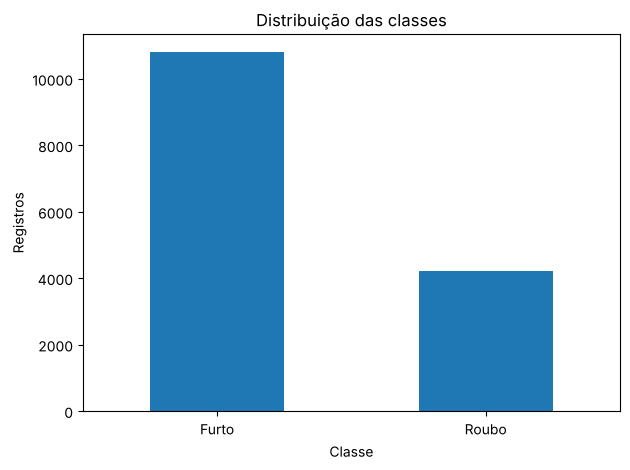

In [4]:
df, _ = train_test_split(df, train_size=15000, stratify=df['classe'], random_state=SEMENTE)
df = df.reset_index(drop=True)
print('Total da amostra:', len(df))
print('Distribuição:')
print(df['classe'].map({0: 'Furto', 1: 'Roubo'}).value_counts())
print('Período não informado:', (df['periodo'] == 'NAO INFORMADO').sum(), 'registros')
ax = df['classe'].map({0: 'Furto', 1: 'Roubo'}).value_counts().plot(kind='bar', title='Distribuição das classes')
ax.set_xlabel('Classe')
ax.set_ylabel('Registros')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 5. Separação em treino, validação e teste
São **70% para treino**, **15% para validação** e **15% para teste**, sempre com estratificação. O conjunto de teste não será utilizado para escolher a rede. O codificador será ajustado exclusivamente com os registros de treino, evitando *data leakage*.

In [5]:
treino, restante = train_test_split(df, test_size=0.30, stratify=df['classe'], random_state=SEMENTE)
validacao, teste = train_test_split(restante, test_size=0.50, stratify=restante['classe'], random_state=SEMENTE)
print(f'Treino: {len(treino)} | Validação: {len(validacao)} | Teste: {len(teste)}')

#Para o site não ficar com centenas de bairros, usamos categorias comuns DO TREINO.
limites = {'bairro': 35, 'tipo_local': 15}
categorias = {}
for coluna in ATRIBUTOS:
    comuns = treino[coluna].value_counts().head(limites.get(coluna, treino[coluna].nunique())).index.tolist()
    for extra in ['NAO INFORMADO', 'OUTROS']:
        if extra not in comuns:
            comuns.append(extra)
    categorias[coluna] = sorted(set(comuns))
    for parte in [treino, validacao, teste]:
        parte.loc[:, coluna] = parte[coluna].where(parte[coluna].isin(comuns), 'OUTROS')

#Atributos categóricos são transformados em colunas binárias pelo OneHotEncoder.
codificador = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
x_train = codificador.fit_transform(treino[ATRIBUTOS]).astype('float32')
x_val = codificador.transform(validacao[ATRIBUTOS]).astype('float32')
x_test = codificador.transform(teste[ATRIBUTOS]).astype('float32')
y_train = treino['classe'].to_numpy().astype('float32')
y_val = validacao['classe'].to_numpy().astype('float32')
y_test = teste['classe'].to_numpy().astype('float32')
print('Número de entradas após One-Hot:', x_train.shape[1])
print('Shapes:', x_train.shape, x_val.shape, x_test.shape)
#No site aparecem somente categorias realmente vistas pelo codificador no treino.
categorias = {coluna: sorted(list(opcoes)) for coluna, opcoes in zip(ATRIBUTOS, codificador.categories_)}
print('Escalonamento: não é necessário porque as entradas são binárias (0 ou 1).')


Treino: 10500 | Validação: 2250 | Teste: 2250


Número de entradas após One-Hot: 65
Shapes: (10500, 65) (2250, 65) (2250, 65)
Escalonamento: não é necessário porque as entradas são binárias (0 ou 1).


### 5.1 Exploração dos atributos (somente treino)
Antes de treinar, vale perguntar: **o que cada atributo diz sobre a classe?** Os gráficos mostram a porcentagem de roubo em cada categoria. A linha tracejada é a média geral do treino: barras bem acima ou abaixo dela indicam atributos que ajudam a separar as classes. Só o conjunto de treino é usado aqui, para não "espiar" a validação nem o teste.

Roubos no treino: 28.0% | furtos: 72.0%


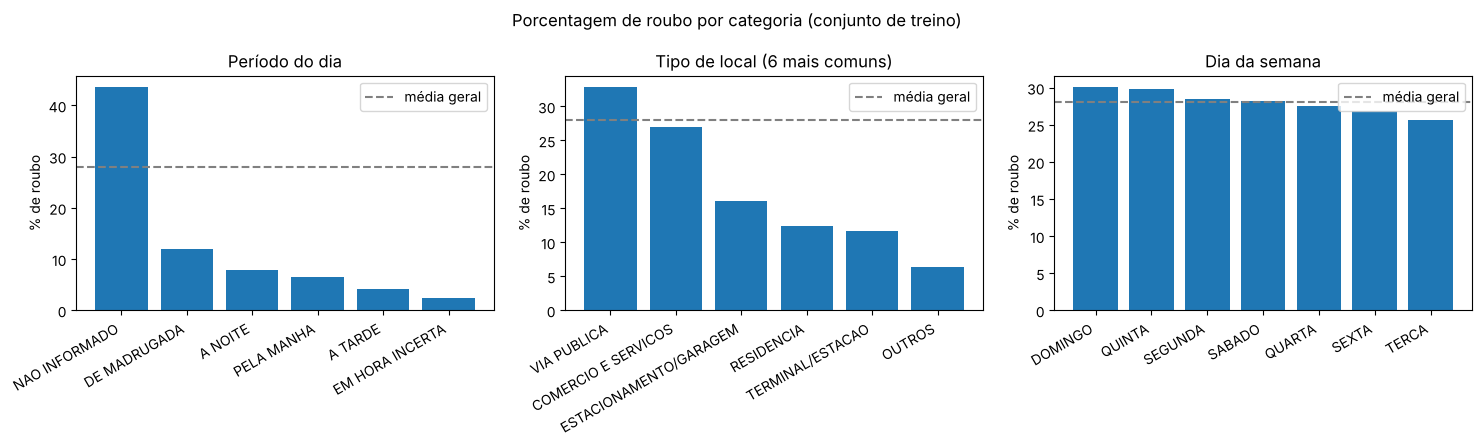

,registros,roubos,% de roubo
periodo,,,
NAO INFORMADO,6031,2632,43.6
A TARDE,1301,55,4.2
A NOITE,1271,100,7.9
PELA MANHA,1163,76,6.5
DE MADRUGADA,651,78,12.0
EM HORA INCERTA,83,2,2.4


Registros sem período informado: 57.4% do treino
Roubos que estão sem período informado: 89.4% de todos os roubos
% de roubo sem período: 43.6% | com período informado: 7.0%


,registros,roubos,% de roubo
tipo_local,,,
VIA PUBLICA,8176,2689,32.9
TERMINAL/ESTACAO,895,105,11.7
OUTROS,787,50,6.4
RESIDENCIA,161,20,12.4
COMERCIO E SERVICOS,126,34,27.0
ESTACIONAMENTO/GARAGEM,81,13,16.0


dia_semana,SEGUNDA,TERCA,QUARTA,QUINTA,SEXTA,SABADO,DOMINGO
% de roubo,28.5,25.6,27.6,29.8,26.9,28.3,30.1


In [6]:
# Exploração dos atributos usando SOMENTE o conjunto de treino.
taxa_geral = treino['classe'].mean()
print(f'Roubos no treino: {taxa_geral:.1%} | furtos: {1 - taxa_geral:.1%}')

fig, eixos = plt.subplots(1, 3, figsize=(15, 4.5))
for eixo, coluna, titulo in zip(eixos, ['periodo', 'tipo_local', 'dia_semana'],
                                ['Período do dia', 'Tipo de local (6 mais comuns)', 'Dia da semana']):
    resumo = treino.groupby(coluna)['classe'].agg(taxa='mean', registros='size')
    if coluna == 'tipo_local':
        resumo = resumo.sort_values('registros', ascending=False).head(6)
    resumo = resumo.sort_values('taxa', ascending=False)
    eixo.bar(resumo.index, resumo['taxa'] * 100)
    eixo.axhline(taxa_geral * 100, color='gray', linestyle='--', label='média geral')
    eixo.set_title(titulo)
    eixo.set_ylabel('% de roubo')
    plt.setp(eixo.get_xticklabels(), rotation=30, ha='right')
    eixo.legend()
fig.suptitle('Porcentagem de roubo por categoria (conjunto de treino)')
plt.tight_layout()
plt.show()

periodo = treino.groupby('periodo')['classe'].agg(registros='size', roubos='sum')
periodo['% de roubo'] = (periodo['roubos'] / periodo['registros'] * 100).round(1)
display(periodo.sort_values('registros', ascending=False))

sem_periodo = treino['periodo'] == 'NAO INFORMADO'
print(f"Registros sem período informado: {sem_periodo.mean():.1%} do treino")
print(f"Roubos que estão sem período informado: {treino.loc[sem_periodo, 'classe'].sum() / treino['classe'].sum():.1%} de todos os roubos")
print(f"% de roubo sem período: {treino.loc[sem_periodo, 'classe'].mean():.1%} | com período informado: {treino.loc[~sem_periodo, 'classe'].mean():.1%}")

tipo = treino.groupby('tipo_local')['classe'].agg(registros='size', roubos='sum')
tipo['% de roubo'] = (tipo['roubos'] / tipo['registros'] * 100).round(1)
display(tipo.sort_values('registros', ascending=False).head(6))

ordem_dias = ['SEGUNDA', 'TERCA', 'QUARTA', 'QUINTA', 'SEXTA', 'SABADO', 'DOMINGO']
dia = (treino.groupby('dia_semana')['classe'].mean() * 100).round(1).reindex(ordem_dias)
display(dia.to_frame('% de roubo').T)

**O que a exploração mostra (treino):**
- Os roubos são 28,0% do treino e os furtos, 72,0%: as classes são **desbalanceadas**.
- **O período do dia é o atributo mais informativo, mas de um jeito inesperado.** 57,4% dos registros têm período `NAO INFORMADO` e eles concentram 89,4% de todos os roubos (43,6% desses registros são roubo). Quando o período é informado, só 7,0% são roubo.
- **Tipo de local:** `VIA PUBLICA` é 77,9% do treino e tem 32,9% de roubo; terminais/estações (11,7%), residências (12,4%) e "outros" (6,4%) têm bem menos.
- **Dia da semana:** a porcentagem de roubo fica entre 25,6% e 30,1% em todos os dias, ou seja, quase não separa as classes.

**Cuidado ao interpretar:** `NAO INFORMADO` no período não é uma característica do crime e sim de **como o boletim foi preenchido**. Isso não é vazamento da resposta (a natureza da ocorrência não entra como entrada), mas a rede vai aprender essa relação, e ela é uma limitação da base.

## 6. Arquiteturas MLP e configurações de treinamento
Comparei três redes, mudando o número de camadas/neurônios. Mantemos iguais a divisão dos dados, perda **binary cross-entropy**, otimizador **Adam**, `learning_rate=0.001`, `batch_size=64` e limite de **25 épocas**. A saída `sigmoid` produz valor entre 0 e 1: por padrão, valores ≥ 0,5 são classificados como roubo (na seção 7.2 esse limiar é reavaliado usando a validação).

| Rede | Camadas ocultas | Objetivo |
|---|---|---|
| A | Dense(16, ReLU) | Modelo simples de comparação |
| B | Dense(32, ReLU), Dense(16, ReLU) | Testar mais capacidade de aprendizado |
| C | Dense(64, ReLU), Dropout(0.25), Dense(32, ReLU) | Testar rede maior com regularização |

O `EarlyStopping` interrompe o treino se a perda de validação não melhorar durante quatro épocas e restaura os melhores pesos.

In [7]:
def criar_modelo(nome, entradas):
    keras.utils.set_random_seed(SEMENTE)
    modelo = keras.Sequential([layers.Input(shape=(entradas,))])
    if nome == 'A':
        modelo.add(layers.Dense(16, activation='relu'))
    elif nome == 'B':
        modelo.add(layers.Dense(32, activation='relu'))
        modelo.add(layers.Dense(16, activation='relu'))
    elif nome == 'C':
        modelo.add(layers.Dense(64, activation='relu'))
        modelo.add(layers.Dropout(0.25))
        modelo.add(layers.Dense(32, activation='relu'))
    modelo.add(layers.Dense(1, activation='sigmoid'))
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                   loss='binary_crossentropy', metrics=['accuracy'])
    return modelo

def avaliar(modelo, x, y):
    probabilidades = modelo.predict(x, verbose=0).reshape(-1)
    previsoes = (probabilidades >= 0.5).astype(int)
    resultado = {
        'acuracia': accuracy_score(y, previsoes),
        'precision': precision_score(y, previsoes, zero_division=0),
        'recall': recall_score(y, previsoes, zero_division=0),
        'f1_score': f1_score(y, previsoes, zero_division=0)
    }
    return resultado, previsoes

modelos = {}
historicos = {}
comparacoes = []
for nome in ['A', 'B', 'C']:
    print('\nTreinando arquitetura', nome)
    rede = criar_modelo(nome, x_train.shape[1])
    parada = keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
    historico = rede.fit(x_train, y_train, validation_data=(x_val, y_val),
                         epochs=25, batch_size=64, callbacks=[parada], verbose=2)
    metricas, _ = avaliar(rede, x_val, y_val)
    comparacoes.append({'arquitetura': nome, 'epocas': len(historico.history['loss']), **metricas})
    modelos[nome] = rede
    historicos[nome] = historico.history



Treinando arquitetura A


Epoch 1/25


165/165 - 2s - 9ms/step - accuracy: 0.6774 - loss: 0.5950 - val_accuracy: 0.7200 - val_loss: 0.5299


Epoch 2/25


165/165 - 0s - 2ms/step - accuracy: 0.7241 - loss: 0.5036 - val_accuracy: 0.7222 - val_loss: 0.5004


Epoch 3/25


... (47 outputs left out)

Epoch 7/25


165/165 - 1s - 5ms/step - accuracy: 0.7380 - loss: 0.4758 - val_accuracy: 0.7253 - val_loss: 0.4910


Epoch 8/25


165/165 - 0s - 3ms/step - accuracy: 0.7383 - loss: 0.4750 - val_accuracy: 0.7222 - val_loss: 0.4912


## 7. Comparação no conjunto de validação
A **classe positiva é roubo**. Como há mais furtos, escolher somente pela acurácia poderia favorecer a classe majoritária. Usamos o **F1-score de validação** (com o limiar padrão de 0,5) para selecionar o modelo e mostramos também acurácia, precision, recall e a **perda de validação**. A última linha da tabela é uma **referência**: um "modelo" que responde sempre *furto*. Ela não participa da escolha.

In [8]:
comparacao = pd.DataFrame(comparacoes).sort_values('f1_score', ascending=False).reset_index(drop=True)
# Menor perda de validação de cada rede (o EarlyStopping restaura os pesos dessa época).
comparacao['perda_validacao'] = comparacao['arquitetura'].map(lambda nome: min(historicos[nome]['val_loss']))

# Referência: responder sempre "furto" (classe 0) para todos os registros.
acc_base_val = float((y_val == 0).mean())
referencia = pd.DataFrame([{'arquitetura': 'Sempre furto', 'epocas': '-', 'acuracia': acc_base_val,
                            'precision': 0.0, 'recall': 0.0, 'f1_score': 0.0, 'perda_validacao': np.nan}])

formatos = {'acuracia': '{:.2%}', 'precision': '{:.2%}', 'recall': '{:.2%}', 'f1_score': '{:.2%}', 'perda_validacao': '{:.4f}'}
display(pd.concat([comparacao, referencia], ignore_index=True).style.format(formatos, na_rep='-'))
melhor = comparacao.iloc[0]['arquitetura']
modelo = modelos[melhor]
print('Modelo selecionado pela validação:', melhor)
print(f'Acurácia de "sempre furto" na validação: {acc_base_val:.2%}')

,arquitetura,epocas,acuracia,precision,recall,f1_score,perda_validacao
0,A,13,72.04%,50.27%,29.79%,37.41%,0.4920
1,C,8,72.49%,53.30%,15.37%,23.86%,0.4898
2,B,7,72.76%,62.50%,7.13%,12.80%,0.4907
3,Sempre furto,-,71.96%,0.00%,0.00%,0.00%,-


Modelo selecionado pela validação: A
Acurácia de "sempre furto" na validação: 71.96%


### 7.1 O que a tabela mostra
- **As três redes são muito parecidas.** A acurácia fica entre 72,04% e 72,76%, quase igual à referência de "sempre furto" (71,96%), e a perda de validação é praticamente a mesma (A: 0,4920; B: 0,4907; C: 0,4898). Aumentar camadas e neurônios ou usar Dropout **não** trouxe ganho relevante: o limite está mais nos atributos do que na capacidade da rede.
- **O F1 muda muito mesmo com perdas quase iguais.** Com o limiar fixo de 0,5, B quase nunca aponta roubo (recall de 7,13%), C aponta pouco (15,37%) e A aponta mais (29,79%). O F1 mede quantos roubos a rede encontra e acerta, por isso A vence nesse critério, mas é uma vantagem pequena, que depende do corte de 0,5.
- **Mudanças e efeitos:** B (duas camadas, 32 e 16 neurônios) subiu a acurácia em 0,72 ponto percentual e derrubou o recall; C (64, Dropout 0,25 e 32) ficou no meio; A (16 neurônios, a mais simples) teve a menor acurácia e o melhor F1.

### 7.2 Ajuste do limiar de decisão (usando só a validação)
A saída da rede é uma probabilidade de roubo. Até aqui a regra foi "probabilidade ≥ 0,5 → roubo". Só que **roubo é a classe menos frequente** (cerca de 28%), então a rede raramente chega a 0,5 e deixa passar muitos roubos (recall baixo).

Uma solução simples, sem mudar a rede, é **escolher outro limiar**. Testamos limiares de 0,05 a 0,60 **na validação** e ficamos com o que dá o maior F1. O teste continua intocado. Para comparar com justiça, o mesmo ajuste é feito nas três redes.

,arquitetura,"F1 com limiar 0,50",limiar ajustado,F1 com limiar ajustado
0,A,37.41%,0.34,59.65%
1,B,12.80%,0.27,59.44%
2,C,23.86%,0.32,59.45%


Limiar escolhido para a MLP A (maior F1 na validação): 0.34
Validação com limiar 0,50: acuracia=72.04% | precision=50.27% | recall=29.79% | f1_score=37.41%
Validação com limiar 0,34: acuracia=69.16% | precision=47.11% | recall=81.30% | f1_score=59.65%


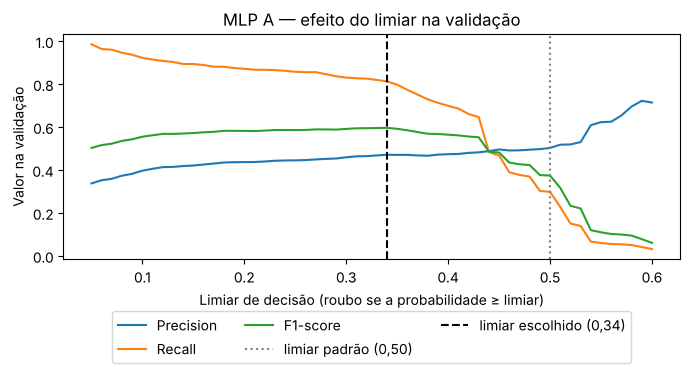

In [9]:
def metricas_por_limiar(y, probabilidades, limiar_teste):
    previsoes = (probabilidades >= limiar_teste).astype(int)
    return {
        'acuracia': accuracy_score(y, previsoes),
        'precision': precision_score(y, previsoes, zero_division=0),
        'recall': recall_score(y, previsoes, zero_division=0),
        'f1_score': f1_score(y, previsoes, zero_division=0)
    }

limiares = np.round(np.arange(0.05, 0.61, 0.01), 2)
tabelas_limiar = {}
resumo_limiares = []
for nome, rede in modelos.items():
    prob_val = rede.predict(x_val, verbose=0).reshape(-1)
    tabela = pd.DataFrame([{'limiar': t, **metricas_por_limiar(y_val, prob_val, t)} for t in limiares])
    tabelas_limiar[nome] = tabela
    melhor_linha = tabela.loc[tabela['f1_score'].idxmax()]
    resumo_limiares.append({
        'arquitetura': nome,
        'F1 com limiar 0,50': metricas_por_limiar(y_val, prob_val, 0.5)['f1_score'],
        'limiar ajustado': melhor_linha['limiar'],
        'F1 com limiar ajustado': melhor_linha['f1_score']
    })
display(pd.DataFrame(resumo_limiares).style.format({'F1 com limiar 0,50': '{:.2%}', 'limiar ajustado': '{:.2f}', 'F1 com limiar ajustado': '{:.2%}'}))

tabela_limiar = tabelas_limiar[melhor]
limiar = float(tabela_limiar.loc[tabela_limiar['f1_score'].idxmax(), 'limiar'])
print(f'Limiar escolhido para a MLP {melhor} (maior F1 na validação): {limiar:.2f}')
prob_val_escolhido = modelo.predict(x_val, verbose=0).reshape(-1)
for rotulo, valor in [('limiar 0,50', 0.5), (f'limiar {limiar:.2f}'.replace('.', ','), limiar)]:
    m = metricas_por_limiar(y_val, prob_val_escolhido, valor)
    print(f'Validação com {rotulo}: ' + ' | '.join(f'{k}={v:.2%}' for k, v in m.items()))

Path('resultados').mkdir(exist_ok=True)
plt.figure(figsize=(7, 4))
plt.plot(tabela_limiar['limiar'], tabela_limiar['precision'], label='Precision')
plt.plot(tabela_limiar['limiar'], tabela_limiar['recall'], label='Recall')
plt.plot(tabela_limiar['limiar'], tabela_limiar['f1_score'], label='F1-score')
plt.axvline(0.5, color='gray', linestyle=':', label='limiar padrão (0,50)')
plt.axvline(limiar, color='black', linestyle='--', label=f'limiar escolhido ({limiar:.2f})'.replace('.', ','))
plt.xlabel('Limiar de decisão (roubo se a probabilidade ≥ limiar)')
plt.ylabel('Valor na validação')
plt.title(f'MLP {melhor} — efeito do limiar na validação')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.tight_layout()
plt.savefig('resultados/limiar_validacao.png', dpi=170, bbox_inches='tight')
plt.show()

**Leitura do ajuste:**
- Depois do ajuste, as três redes ficam praticamente empatadas na validação (F1 de 59,65% para A, 59,44% para B e 59,45% para C). Isso reforça que **a arquitetura não é o gargalo**.
- A continua sendo a de maior F1 também com o limiar ajustado. Como é a rede mais simples e foi escolhida **antes** de olhar o teste, ela é mantida: quando redes diferentes empatam, preferimos a mais simples.
- Para a rede A, o limiar escolhido é **0,34**: o recall de roubo sobe bastante e a precision cai um pouco. É a troca (*trade-off*) esperada.

## 8. Avaliação final — somente no teste
Agora que a arquitetura e o limiar foram escolhidos **com a validação**, o conjunto de **teste**, que ficou separado desde o início, é usado uma única vez para a avaliação final. Mostramos a MLP escolhida com o limiar padrão (0,5) e com o limiar ajustado, ao lado da referência "sempre furto". As matrizes de confusão mostram quais casos a rede confunde.

Métricas finais (teste) — classe positiva: roubo


,modelo,limiar,acuracia,precision,recall,f1_score
0,"Referência: sempre ""furto""",-,72.00%,0.00%,0.00%,0.00%
1,MLP A,"0,50",72.71%,52.31%,28.73%,37.09%
2,MLP A,"0,34",68.80%,46.72%,81.27%,59.33%


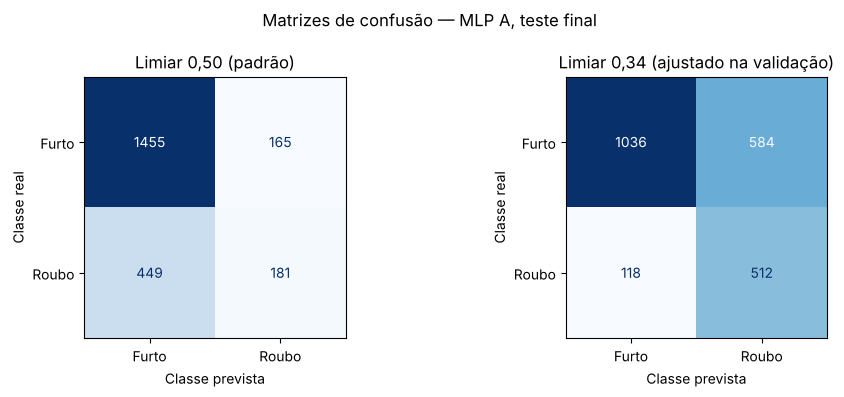

Matriz de confusão com o limiar ajustado (linhas reais, colunas previstas):
[[1036  584]
 [ 118  512]]


In [10]:
probabilidades_teste = modelo.predict(x_test, verbose=0).reshape(-1)
previstos_padrao = (probabilidades_teste >= 0.5).astype(int)
previstos_ajustado = (probabilidades_teste >= limiar).astype(int)

acc_baseline_teste = float((y_test == 0).mean())
metricas_teste_padrao = metricas_por_limiar(y_test, probabilidades_teste, 0.5)
metricas_teste = metricas_por_limiar(y_test, probabilidades_teste, limiar)   # resultado final adotado

tabela_teste = pd.DataFrame([
    {'modelo': 'Referência: sempre "furto"', 'limiar': '-', 'acuracia': acc_baseline_teste, 'precision': 0.0, 'recall': 0.0, 'f1_score': 0.0},
    {'modelo': f'MLP {melhor}', 'limiar': '0,50', **metricas_teste_padrao},
    {'modelo': f'MLP {melhor}', 'limiar': f'{limiar:.2f}'.replace('.', ','), **metricas_teste},
])
print('Métricas finais (teste) — classe positiva: roubo')
display(tabela_teste.style.format({'acuracia': '{:.2%}', 'precision': '{:.2%}', 'recall': '{:.2%}', 'f1_score': '{:.2%}'}))

fig, eixos = plt.subplots(1, 2, figsize=(10, 4))
titulos = ['Limiar 0,50 (padrão)', f'Limiar {limiar:.2f} (ajustado na validação)'.replace('.', ',')]
for eixo, previstos, titulo in zip(eixos, [previstos_padrao, previstos_ajustado], titulos):
    matriz = confusion_matrix(y_test, previstos, labels=[0, 1])
    ConfusionMatrixDisplay(matriz, display_labels=['Furto', 'Roubo']).plot(ax=eixo, cmap='Blues', colorbar=False)
    eixo.set_title(titulo)
    eixo.set_xlabel('Classe prevista')
    eixo.set_ylabel('Classe real')
fig.suptitle(f'Matrizes de confusão — MLP {melhor}, teste final')
plt.tight_layout()
Path('resultados').mkdir(exist_ok=True)
plt.savefig('resultados/matriz_confusao.png', dpi=170, bbox_inches='tight')
plt.show()
print('Matriz de confusão com o limiar ajustado (linhas reais, colunas previstas):')
print(confusion_matrix(y_test, previstos_ajustado, labels=[0, 1]))

## 9. Curvas de treinamento e análise
As curvas permitem comparar o desempenho no treino e na validação. Se a perda de treino diminui, mas a de validação piora, isso pode indicar **overfitting**. Se o modelo vai mal nos dois conjuntos, pode haver **underfitting**. A decisão não deve depender de apenas um número.

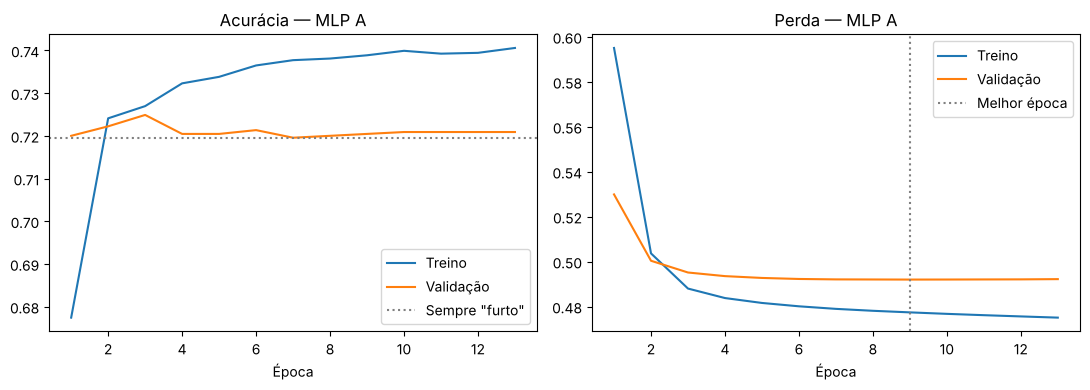

Melhor época (menor perda de validação): 9 de 13
Nessa época: perda treino=0.4774 | perda validação=0.4920
Nessa época: acurácia treino=73.89% | acurácia validação=72.04%
Referência (sempre "furto") na validação: 71.96%


In [11]:
hist = historicos[melhor]
epocas = list(range(1, len(hist['loss']) + 1))
melhor_epoca = int(np.argmin(hist['val_loss'])) + 1   # contagem a partir de 1
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(epocas, hist['accuracy'], label='Treino')
axs[0].plot(epocas, hist['val_accuracy'], label='Validação')
axs[0].axhline(acc_base_val, color='gray', linestyle=':', label='Sempre "furto"')
axs[0].set_title('Acurácia — MLP ' + melhor)
axs[0].set_xlabel('Época')
axs[0].legend()
axs[1].plot(epocas, hist['loss'], label='Treino')
axs[1].plot(epocas, hist['val_loss'], label='Validação')
axs[1].axvline(melhor_epoca, color='gray', linestyle=':', label='Melhor época')
axs[1].set_title('Perda — MLP ' + melhor)
axs[1].set_xlabel('Época')
axs[1].legend()
plt.tight_layout()
plt.savefig('resultados/curvas_treinamento.png', dpi=170, bbox_inches='tight')
plt.show()
ind = melhor_epoca - 1
print(f'Melhor época (menor perda de validação): {melhor_epoca} de {len(hist["loss"])}')
print(f'Nessa época: perda treino={hist["loss"][ind]:.4f} | perda validação={hist["val_loss"][ind]:.4f}')
print(f'Nessa época: acurácia treino={hist["accuracy"][ind]:.2%} | acurácia validação={hist["val_accuracy"][ind]:.2%}')
print(f'Referência (sempre "furto") na validação: {acc_base_val:.2%}')

### Interpretação das curvas
- **Perda:** a perda de treino continua caindo, mas a de validação para de melhorar por volta da época 9 (0,4774 no treino e 0,4920 na validação). O `EarlyStopping` interrompe o treino e restaura os pesos dessa época. A distância entre as curvas é pequena, então **não há overfitting relevante**.
- **Acurácia:** cerca de 74% no treino e 72% na validação. A linha pontilhada mostra que "sempre furto" já dá cerca de 72%. Ou seja, a rede também **não é muito melhor que a referência**, o que aponta para **underfitting por falta de informação nos atributos** (e não por falta de capacidade, já que B e C não melhoraram a perda).
- **Consequência:** a acurácia sozinha esconde o problema. O que mostra se a rede encontra os roubos é o recall, e por isso o limiar foi ajustado na seção 7.2.

## 10. Salvar o modelo e exportar para o site no GitHub Pages
O modelo treinado fica salvo em `.keras`, junto do codificador `joblib`. O próprio notebook também gera `docs/modelo_web.json`, com os pesos das camadas, a ordem exata das categorias do `OneHotEncoder` e o **limiar de decisão** escolhido na validação. O site em HTML e JavaScript aplica o mesmo one-hot, calcula a saída da MLP diretamente no navegador e usa o mesmo limiar, sem servidor Python.

Após treinar novamente, o arquivo `docs/modelo_web.json` deve ser atualizado no repositório para manter o site consistente com o novo modelo.

In [12]:
Path('artefatos').mkdir(exist_ok=True)
modelo.save('artefatos/modelo_mlp.keras')
joblib.dump(codificador, 'artefatos/codificador.joblib')
resumo = {
    'linhas_recebidas': int(len(dados)),
    'registros_capital': int(total_capital),
    'registros_2025_antes_deduplicacao': int(total_2025),
    'boletins_ambiguos_removidos': int(bo_ambiguos),
    'boletins_unicos_apos_filtros': int(total_unicos),
    'total_da_amostra': int(len(df)),
    'furtos_na_amostra': int((df['classe'] == 0).sum()),
    'roubos_na_amostra': int((df['classe'] == 1).sum()),
    'periodo_nao_informado_na_amostra': int((df['periodo'] == 'NAO INFORMADO').sum())
}
manifesto = {
    'projeto': 'Segurança Pública Inteligente - Roubo x Furto',
    'fonte': FONTE,
    'arquivo_utilizado': ARQUIVO.name,
    'recorte': 'Município de São Paulo; fatos de 2025; FURTO - OUTROS e ROUBO - OUTROS',
    'atributos': ATRIBUTOS,
    'categorias': categorias,
    'classe_0': 'Furto', 'classe_1': 'Roubo',
    'arquitetura_escolhida': melhor,
    'registros': resumo,
    'conjuntos': {'treino': len(treino), 'validacao': len(validacao), 'teste': len(teste)},
    'limiar_decisao': float(limiar),
    'referencia_sempre_furto': {'acuracia_validacao': acc_base_val, 'acuracia_teste': acc_baseline_teste},
    'metricas_teste': {chave: float(valor) for chave, valor in metricas_teste.items()},
    'metricas_teste_limiar_0_5': {chave: float(valor) for chave, valor in metricas_teste_padrao.items()},
    'observacao': 'Classifica um registro; não prevê risco de crime futuro.'
}
with open('artefatos/manifesto.json', 'w', encoding='utf-8') as arquivo:
    json.dump(manifesto, arquivo, indent=2, ensure_ascii=False)
comparacao.to_csv('resultados/comparacao_validacao.csv', index=False)
pd.DataFrame([
    {'arquitetura': melhor, 'limiar': 0.5, **metricas_teste_padrao},
    {'arquitetura': melhor, 'limiar': float(limiar), **metricas_teste}
]).to_csv('resultados/metricas_teste.csv', index=False)
with open('resultados/historico_escolhido.json', 'w', encoding='utf-8') as arquivo:
    json.dump({chave: [float(v) for v in valores] for chave, valores in hist.items()}, arquivo, indent=2)
print('Arquivos gerados:')
for arquivo in Path('artefatos').glob('*'):
    print(' ', arquivo)

#Exportação do modelo para o navegador (GitHub Pages, sem servidor Python).
#As categorias seguem a mesma ordem que o OneHotEncoder aprendeu no treino.
pesos = modelo.get_weights()
camadas_web = []
for i in range(0, len(pesos), 2):
    ultima = (i == len(pesos) - 2)
    camadas_web.append({
        'ativacao': 'sigmoid' if ultima else 'relu',
        'pesos': pesos[i].tolist(),
        'bias': pesos[i + 1].tolist()
    })

modelo_web = {
    'versao': 2,
    'nome': 'Segurança Pública Inteligente — São Paulo',
    'arquitetura': melhor,
    'atributos': ATRIBUTOS,
    'categorias': categorias,
    'limiar': float(limiar),
    'camadas': camadas_web,
    'classe_0': 'Furto', 'classe_1': 'Roubo',
    'descricao': 'Classifica registros; não prevê crimes futuros.'
}
Path('docs').mkdir(exist_ok=True)
with open('docs/modelo_web.json', 'w', encoding='utf-8') as arquivo:
    json.dump(modelo_web, arquivo, ensure_ascii=False, separators=(',', ':'))
print('Modelo do site gerado: docs/modelo_web.json')

#Arquivo pequeno para atualizar o modelo depois de um novo treino no Colab.
import zipfile
with zipfile.ZipFile('modelo_para_site.zip', 'w', zipfile.ZIP_DEFLATED) as zip_modelo:
    for arquivo in Path('artefatos').glob('*'):
        zip_modelo.write(arquivo)
    zip_modelo.write('docs/modelo_web.json')
print('Arquivo para atualizar o site: modelo_para_site.zip')


Arquivos gerados:
  artefatos/manifesto.json
  artefatos/modelo_mlp.keras
  artefatos/codificador.joblib
Modelo do site gerado: docs/modelo_web.json
Arquivo para atualizar o site: modelo_para_site.zip


## 11. Teste de exemplos usando o modelo salvo
Este teste **recarrega do disco** o modelo `.keras` e o codificador `joblib` e classifica três exemplos: o do enunciado (Pinheiros, sexta-feira, noite, via pública), o mesmo com o período não informado e o primeiro registro da validação. Serve só para verificar se os arquivos salvos funcionam juntos; não é uma nova avaliação do desempenho.

**Como interpretar:** a rede estima, para um registro com essas características, a probabilidade de ele ser um roubo. Isso **não** é a chance de acontecer um roubo naquele bairro e horário.

In [13]:
modelo_salvo = keras.saving.load_model('artefatos/modelo_mlp.keras')
codificador_salvo = joblib.load('artefatos/codificador.joblib')

exemplos = pd.DataFrame([
    {'bairro': 'PINHEIROS', 'periodo': 'A NOITE', 'tipo_local': 'VIA PUBLICA', 'dia_semana': 'SEXTA'},
    {'bairro': 'PINHEIROS', 'periodo': 'NAO INFORMADO', 'tipo_local': 'VIA PUBLICA', 'dia_semana': 'SEXTA'},
])
exemplos = pd.concat([exemplos, validacao[ATRIBUTOS].iloc[[0]]], ignore_index=True)

entradas = codificador_salvo.transform(exemplos[ATRIBUTOS]).astype('float32')
probabilidades = modelo_salvo.predict(entradas, verbose=0).reshape(-1)

resultado = exemplos.copy()
resultado['prob. roubo'] = [f'{p:.2%}' for p in probabilidades]
resultado['prob. furto'] = [f'{1 - p:.2%}' for p in probabilidades]
resultado['classe estimada'] = ['Roubo' if p >= limiar else 'Furto' for p in probabilidades]
print(f'Limiar de decisão usado: {limiar:.2f} (roubo se a probabilidade de roubo for maior ou igual a ele)')
display(resultado)

Limiar de decisão usado: 0.34 (roubo se a probabilidade de roubo for maior ou igual a ele)


,bairro,periodo,tipo_local,dia_semana,prob. roubo,prob. furto,classe estimada
0,PINHEIROS,A NOITE,VIA PUBLICA,SEXTA,8.35%,91.65%,Furto
1,PINHEIROS,NAO INFORMADO,VIA PUBLICA,SEXTA,44.70%,55.30%,Roubo
2,SANTANA,PELA MANHA,OUTROS,SABADO,3.47%,96.53%,Furto


## 12. Conclusão e limitações

**Resultados.** Três MLPs foram treinadas e comparadas na validação. A rede **A** (uma camada oculta de 16 neurônios) teve o maior F1 e foi escolhida; as três ficaram muito parecidas na perda de validação e, depois do ajuste do limiar, também no F1. No teste, com o limiar ajustado para 0,34, a MLP A obteve acurácia de 68,80%, precision de 46,72%, recall de 81,27% e F1 de 59,33%. Com o limiar padrão de 0,5 foram 72,71%, 52,31%, 28,73% e 37,09%.

**Como ler esses números.** Responder sempre "furto" já dá 72,00% de acurácia no teste, então a acurácia sozinha não mede bem este problema. O que melhorou com o limiar foi a capacidade de encontrar roubos (recall de 28,73% para 81,27%), ao custo de mais alarmes falsos (precision de 52,31% para 46,72%) e de um pouco de acurácia.

**Por que o desempenho é limitado.** Os atributos carregam pouca informação: o dia da semana quase não separa as classes e o período do dia está `NAO INFORMADO` em cerca de 57% dos registros. Essa ausência está muito ligada a roubo, ou seja, a rede aprende em parte *como o boletim foi preenchido*, e não só características do fato. Redes maiores não resolvem isso.

**Limitações.** São boletins registrados, não todos os crimes; o recorte inclui apenas duas naturezas (`- OUTROS`); o limiar foi escolhido com uma única divisão dos dados; o modelo pode apresentar erros de classificação e **não deve ser usado para tomar decisões reais sobre segurança pública**. A rede classifica um registro; ela **não prevê** se um crime vai acontecer.

**Uso de IA generativa:** Um assistente de IA generativa apoiou a escrita e a revisão do código do notebook e do site, revisão da análise dos resultados. Os números deste notebook vêm da execução do código com os dados oficiais, e a inferência do site foi conferida contra o modelo Keras salvo.

**Referência:** SECRETARIA DA SEGURANÇA PÚBLICA DO ESTADO DE SÃO PAULO. *Estatísticas — Consultas*. https://www.ssp.sp.gov.br/estatistica/consultas.